In [1]:
# I load the libraries needed so I can train the models and display the results.
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# I set a seed ( pseudo randon number generator ) so repeated runs are easier to compare.
tf.keras.utils.set_random_seed(42)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Available GPUs: []


In [2]:
# I load CIFAR-10 ( 10 classes ) so I have labeled images for training and testing.
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2818s 17us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


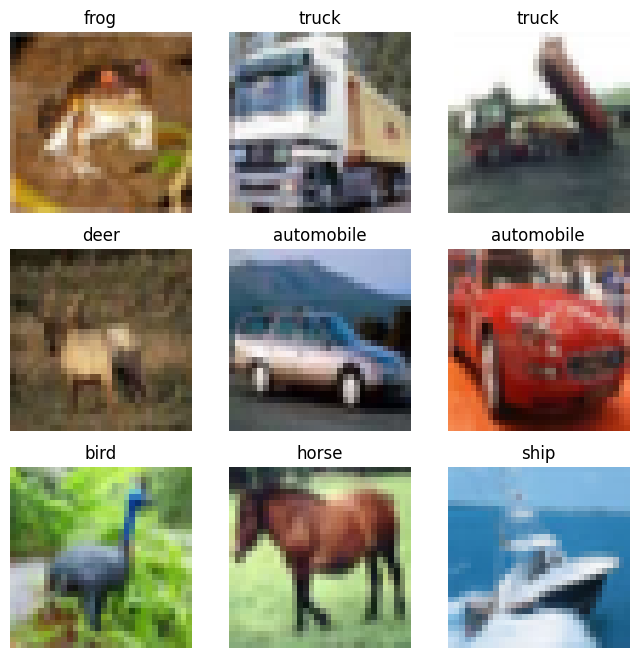

In [3]:
# I show a few images and labels so I can check what the dataset contains. ( A trial run )
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.show()

In [4]:
# I scale pixels to values between zero and one so training is easier.
# Small, uniform inputs (between 0 and 1) help gradient descent find the optimal weights much faster and smoother.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Smallest training pixel value:", x_train.min())
print("Largest training pixel value:", x_train.max())

Smallest training pixel value: 0.0
Largest training pixel value: 1.0


In [5]:
# I keep 5,000 training images for validation so I can choose settings without using the test set.
x_val = x_train[-5000:]
y_val = y_train[-5000:]

x_train = x_train[:-5000]
y_train = y_train[:-5000]

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Test images:", x_test.shape)

Training images: (45000, 32, 32, 3)
Validation images: (5000, 32, 32, 3)
Test images: (10000, 32, 32, 3)


In [6]:
# I build a small model so I have a baseline to compare with the improved model. ( a  reference point )
model_a = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10)
])

model_a.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# I use Adam ( Adaptive Moment Estimation ) and a loss for integer labels so the baseline can learn from class scores and minimize the loss function.
model_a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [8]:
# I train the baseline for ten epochs so I can compare its results with Run B.
history_a = model_a.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 57s 78ms/step - accuracy: 0.4688 - loss: 1.4790 - val_accuracy: 0.5510 - val_loss: 1.2748
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.6022 - loss: 1.1381 - val_accuracy: 0.6234 - val_loss: 1.0752
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.6525 - loss: 0.9986 - val_accuracy: 0.6568 - val_loss: 0.9851
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 72ms/step - accuracy: 0.6850 - loss: 0.9084 - val_accuracy: 0.6708 - val_loss: 0.9420
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 52s 74ms/step - accuracy: 0.7107 - loss: 0.8354 - val_accuracy: 0.6780 - val_loss: 0.9242
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 74ms/step - accuracy: 0.7321 - loss: 0.7730 - val_accuracy: 0.6908 - val_loss: 0.9062
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 80s 72ms/step - accuracy: 0.7536 - loss: 0.7132 - val_accuracy: 0.6944 - val_loss: 0.9005
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.7715 - loss: 0.6598 - 

In [9]:
# I evaluate the baseline on unseen images so I can measure its test accuracy.
test_loss_a, test_accuracy_a = model_a.evaluate(x_test, y_test)

print(f"Run A test accuracy: {test_accuracy_a * 100:.2f}%")
print(f"Run A test loss: {test_loss_a:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6803 - loss: 1.0127
Run A test accuracy: 68.03%
Run A test loss: 1.0127


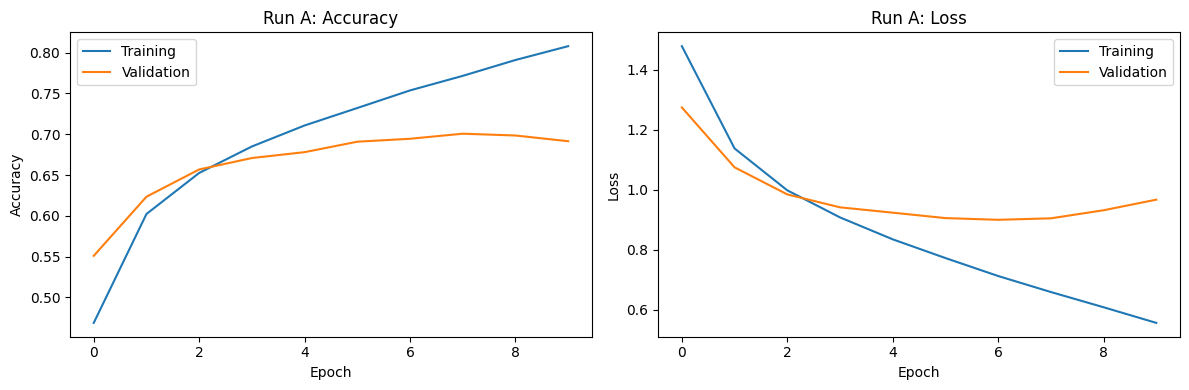

In [10]:
# I plot baseline accuracy and loss so I can see how learning changes over time.
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_a.history["accuracy"], label="Training")
plt.plot(history_a.history["val_accuracy"], label="Validation")
plt.title("Run A: Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_a.history["loss"], label="Training")
plt.plot(history_a.history["val_loss"], label="Validation")
plt.title("Run A: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# I flip and shift training images so the model learns from small changes.
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomTranslation(0.1, 0.1, fill_mode="reflect")
], name="augmentation")

In [12]:
# I build a deeper model so it can learn more detailed image patterns.
model_b = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3)),
    augmentation
], name="improved_cifar10")

# I use two convolutions in each block to learn patterns before shrinking the images.
for filters, dropout_rate in [(32, 0.2), (64, 0.3), (128, 0.4)]:
    for _ in range(2):
        model_b.add(tf.keras.layers.Conv2D(
            filters, (3, 3), padding="same", use_bias=False,
            kernel_initializer="he_normal"
        ))
        # I normalize the values to help training stay stable.
        model_b.add(tf.keras.layers.BatchNormalization())
        model_b.add(tf.keras.layers.Activation("relu"))
    model_b.add(tf.keras.layers.MaxPooling2D((2, 2)))
    # I drop some values during training to reduce memorization.
    model_b.add(tf.keras.layers.Dropout(dropout_rate))

# I combine the learned patterns to produce a score for each of the ten classes.
model_b.add(tf.keras.layers.Flatten())
model_b.add(tf.keras.layers.Dense(128, use_bias=False, kernel_initializer="he_normal"))
model_b.add(tf.keras.layers.BatchNormalization())
model_b.add(tf.keras.layers.Activation("relu"))
model_b.add(tf.keras.layers.Dropout(0.5))
model_b.add(tf.keras.layers.Dense(10))
model_b.summary()

Model: "improved_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [13]:
# I use Adam and a loss for raw class scores so the improved model learns the correct labels.
model_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [ ]:
# I reduce the learning rate when validation loss stalls so the model can improve in smaller steps.
callbacks_b = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1
    ),
    # I restore the best validation weights so extra training does not keep a worse model.
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True, verbose=1
    ),
    # I save the best weights so I can reuse them after training.
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_b.weights.h5", monitor="val_loss",
        save_best_only=True, save_weights_only=True, verbose=1
    )
]

# I allow up to 60 epochs because the deeper model needs more time to learn.
history_b = model_b.fit(
    x_train, y_train,
    epochs=60,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=callbacks_b,
    shuffle=True
)

Epoch 1/60
257/704 ━━━━━━━━━━━━━━━━━━━━ 3:51 517ms/step - accuracy: 0.2400 - loss: 2.2516

In [ ]:
# I check the saved best weights on unseen test images to measure the final accuracy.
model_b.load_weights("best_model_b.weights.h5")
test_loss_b, test_accuracy_b = model_b.evaluate(x_test, y_test, verbose=2)

print(f"Run A test accuracy: {test_accuracy_a * 100:.2f}%")
print(f"Run B test accuracy: {test_accuracy_b * 100:.2f}%")
print(f"Run B test loss: {test_loss_b:.4f}")
print("Above 75%:", test_accuracy_b > 0.75)

In [ ]:
# I count predictions for each class pair so I can see which classes the model confuses.
import seaborn as sns

scores = model_b.predict(x_test)
predicted_labels = np.argmax(scores, axis=1)

cm = tf.math.confusion_matrix(
    labels=y_test.reshape(-1),
    predictions=predicted_labels,
    num_classes=10
).numpy()

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Run B: Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# I find the most confused pair so I can identify the largest classification problem.
errors = cm.copy()
np.fill_diagonal(errors, 0)

pair_errors = errors + errors.T

i, j = np.unravel_index(
    np.argmax(pair_errors),
    pair_errors.shape
)

print(f"Most confused pair: {class_names[i]} and {class_names[j]}")
print(f"{class_names[i]} predicted as {class_names[j]}: {errors[i, j]}")
print(f"{class_names[j]} predicted as {class_names[i]}: {errors[j, i]}")
print(f"Total confusion between them: {pair_errors[i, j]}")

In [ ]:
# I plot each run using its own epoch count so different training lengths work correctly.
plt.figure(figsize=(14, 10))
for panel, (metric, title, ylabel) in enumerate([
    ("accuracy", "Training Accuracy", "Accuracy"),
    ("val_accuracy", "Validation Accuracy", "Accuracy"),
    ("loss", "Training Loss", "Loss"),
    ("val_loss", "Validation Loss", "Loss")
], start=1):
    plt.subplot(2, 2, panel)
    for history, label in [(history_a, "Run A"), (history_b, "Run B")]:
        values = history.history[metric]
        plt.plot(range(1, len(values) + 1), values, label=label)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()

plt.tight_layout()
plt.savefig("run_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# I save the confusion matrix so I can include the class errors in my report.
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Run B: Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()